# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
%pip install pandas numpy plotly 

In [2]:
%pip install "nbformat>=4.2.0"

In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


In [4]:
df.head(5) 

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area,Density,World share (%)
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,0.00


In [7]:
df.columns

Index(['Rank', 'CCA3', 'Country', 'Capital', 'Continent', '2022 Population',
       '2020 Population', '2015 Population', '2010 Population',
       '2000 Population', '1990 Population', '1980 Population',
       '1970 Population', 'Area', 'Density', 'World share (%)'],
      dtype='str')

---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*
1. **Chart type: line chart.** The question is about growth over time, and a line chart shows trend and direction better than other chart types.
2. **Index to 1970 = 100.** Asia has billions of people and Oceania only millions, so absolute values would flatten the small continents. Dividing each continent's population by its 1970 value and multiplying by 100 puts all of them on the same scale.
3. **Highlight the answer.** The fastest-growing continent is drawn thick and red, and the others thin and gray. Growth % labels at the line ends replace a legend, so the ranking can be read directly.

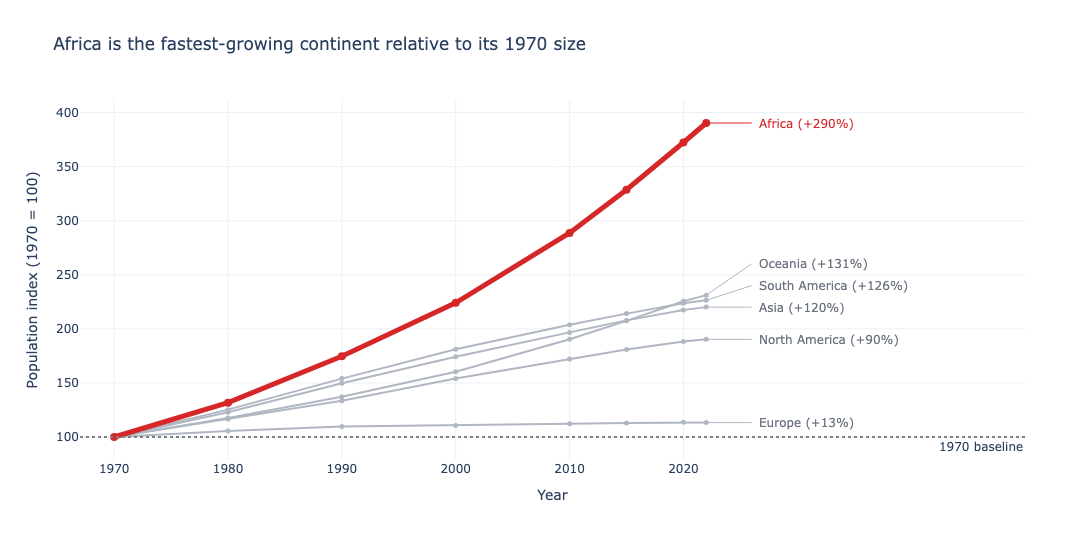

In [6]:
import plotly.graph_objects as go


min_gap = 20                                   # minimum spacing between labels (index units)
end_vals = index_df[2022].sort_values()        # lowest to highest
label_y, prev = {}, None
for c, y in end_vals.items():
    if prev is not None and y - prev < min_gap:
        y = prev + min_gap
    label_y[c] = y
    prev = y


fig = go.Figure()
for continent in index_df.sort_values(2022).index:      # fastest drawn last, on top
    is_fast = continent == fastest
    fig.add_trace(go.Scatter(
        x=years, y=index_df.loc[continent],
        mode="lines+markers", name=continent,
        line=dict(color=palette[continent], width=5 if is_fast else 2),
        marker=dict(size=8 if is_fast else 5),
        hovertemplate=f"{continent}<br>%{{x}}: %{{y:.0f}}<extra></extra>",
    ))

    # Leader line from the real line end to the (shifted) label position
    fig.add_shape(
        type="line",
        x0=2022, y0=index_df.loc[continent, 2022],
        x1=2026, y1=label_y[continent],
        line=dict(color=palette[continent], width=1),
    )
    fig.add_annotation(
        x=2026.5, y=label_y[continent],
        text=f"{continent} (+{growth_pct[continent]:,.0f}%)",
        showarrow=False, xanchor="left",
        font=dict(color="#D62728" if is_fast else "#6B7280", size=12),
    )

fig.add_hline(y=100, line_dash="dot", line_color="gray",
              annotation_text="1970 baseline", annotation_position="bottom right")

fig.update_layout(
    title=f"{fastest} is the fastest-growing continent relative to its 1970 size",
    xaxis=dict(title="Year", tickmode="array",
               tickvals=[1970, 1980, 1990, 2000, 2010, 2020],   # fewer ticks, no 2020/2022 clash
               range=[1967, 2050]),
    yaxis=dict(title="Population index (1970 = 100)"),
    template="plotly_white", showlegend=False, height=540,
    margin=dict(r=40),
)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*


**Chart: horizontal bar chart, sorted from largest to smallest gain.**

1. **Fits the question:** Q2 asks for a ranking of 15 countries by one number (people added). Bars compare lengths against a common zero baseline, which is the most accurate way to compare magnitudes.
2. **Horizontal, not vertical:** Country names are long, so they stay readable on the y-axis without rotating. The top 15 reads naturally from top to bottom.
3. **Sorted by value:** The ranking can be read at a glance, with no legend lookup needed.
4. **Highlighting answers the second part:** African countries are drawn in a strong color and all others in gray. The number of African bars is the answer to "how many are in Africa?", and the count is shown in the title.
5. **Absolute gain, not percent:** The question says "added the most people", so the metric is 2022 population minus 1970 population. A percentage would favor small countries.
6. **Honest axis:** The bars start at zero, and value labels at the bar ends (in millions) remove the need to estimate from gridlines.

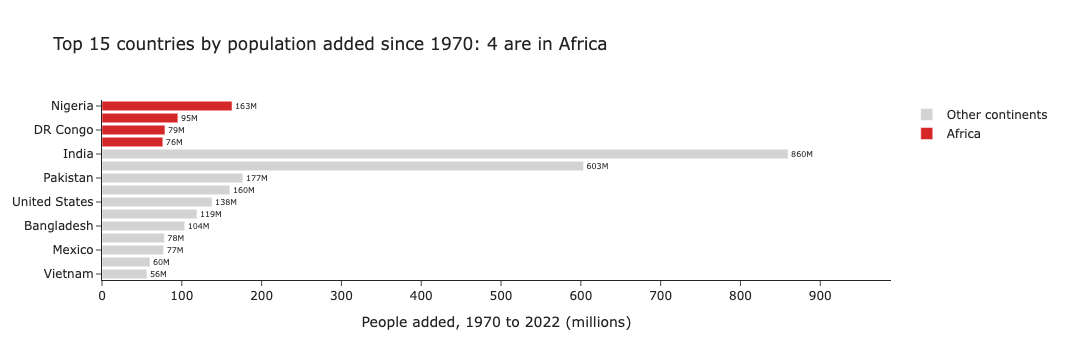

4 of the top 15 are in Africa: ['Egypt', 'DR Congo', 'Ethiopia', 'Nigeria']


In [9]:
#YOUR CODE HERE
d = df.copy()
d["Added"] = d["2022 Population"] - d["1970 Population"]
d["Added_M"] = d["Added"] / 1e6

top15 = d.nlargest(15, "Added").sort_values("Added")
top15["Group"] = np.where(top15["Continent"] == "Africa", "Africa", "Other continents")
n_africa = (top15["Group"] == "Africa").sum()

fig = px.bar(top15, x="Added_M", y="Country", orientation="h",
             color="Group",
             color_discrete_map={"Africa": "#d62728", "Other continents": "lightgray"},
             text=top15["Added_M"].map(lambda v: f"{v:,.0f}M"),
             title=f"Top 15 countries by population added since 1970: {n_africa} are in Africa")
fig.update_traces(textposition="outside")
fig.update_layout(template="simple_white",
                  xaxis_title="People added, 1970 to 2022 (millions)",
                  yaxis_title=None,
                  legend_title_text="",
                  xaxis=dict(range=[0, top15["Added_M"].max() * 1.15]))
fig.show()

print(f"{n_africa} of the top 15 are in Africa:",
      list(top15[top15["Group"] == "Africa"]["Country"]))

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*
1. **Fits the question:** Q3 asks whether two numeric variables are related. A scatter plot is the standard chart for a relationship between two variables, and each dot is one country, so nothing is aggregated away.
2. **Log scales on both axes:** Area and population both span several orders of magnitude (from tiny island states to China and Russia). On linear axes almost all countries would be squashed into the bottom-left corner. On log axes the pattern becomes visible.
3. **Color by continent:** This answers "does it differ by continent?". Clusters or different trend lines per continent show up directly. Color is used for the categorical split only, so I did not use a bubble chart (the size channel would add clutter).
4. **Trend line:** One overall trend line (on the log values) shows the general relationship. Countries far above or below it break the pattern.
5. **Outliers labeled:** The countries with the largest residuals from the trend are labeled, which answers "which countries clearly break the pattern?". Labeling only these keeps the chart readable.
6. **Honest reading:** The trend is weak or moderate rather than strong, so the chart title states what the data shows instead of implying a strong rule.

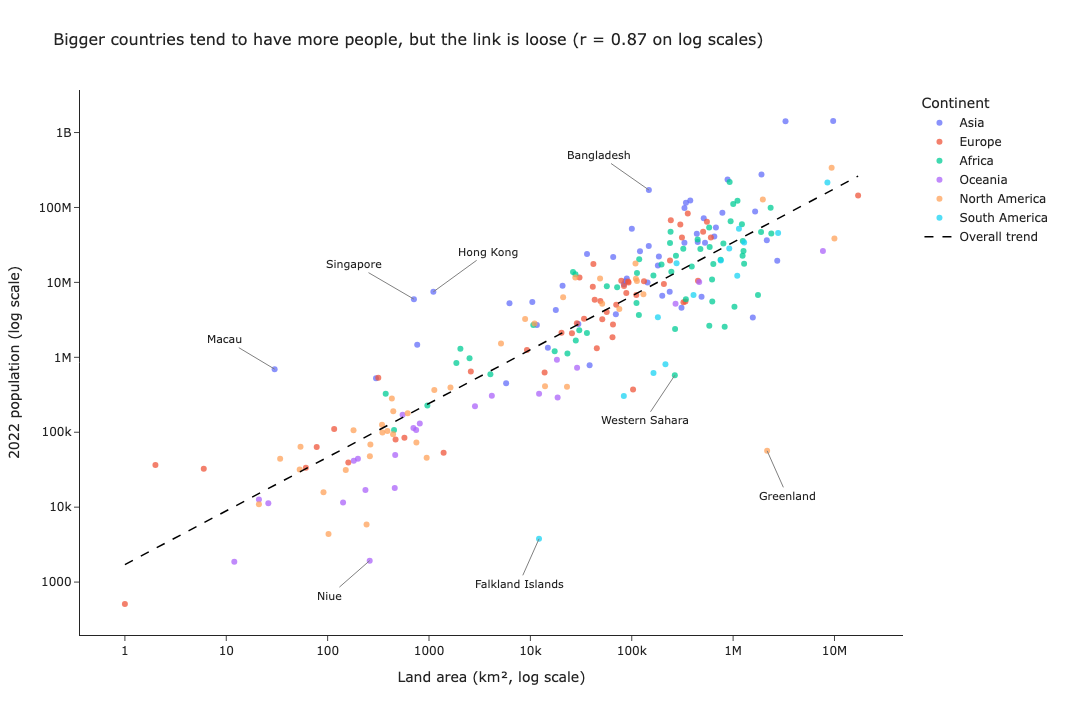

In [11]:
# Q3
# YOUR CODE HERE
d = df[["Country", "Continent", "Area", "2022 Population"]].dropna().copy()
d = d[(d["Area"] > 0) & (d["2022 Population"] > 0)]
d["Pop_2022"] = d["2022 Population"]

# 1. Fit a trend on the log values: log10(pop) = a + b * log10(area)
x, y = np.log10(d["Area"]), np.log10(d["Pop_2022"])
b, a = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
d["Residual"] = y - (a + b * x)

# 2. Outliers = 8 largest residuals in either direction
outliers = d.reindex(d["Residual"].abs().nlargest(8).index)

# 3. Scatter plot, log-log, colored by continent
fig = px.scatter(
    d, x="Area", y="Pop_2022", color="Continent",
    hover_name="Country", log_x=True, log_y=True, opacity=0.75,
    labels={"Area": "Land area (km², log scale)",
            "Pop_2022": "2022 population (log scale)"},
    title=f"Bigger countries tend to have more people, but the link is loose (r = {r:.2f} on log scales)",
)

# 4. Trend line
xs = np.linspace(x.min(), x.max(), 100)
fig.add_scatter(x=10**xs, y=10**(a + b * xs), mode="lines",
                line=dict(color="black", dash="dash", width=1.5),
                name="Overall trend", hoverinfo="skip")

# 5. Label the outliers, each with its own offset in pixels
#    (negative ay = label above the point, positive ay = below;
#     negative ax = label to the left, positive ax = to the right)
offsets = {
    "Singapore":        (-60, -35),
    "Hong Kong":        ( 55, -40),
    "Macau":            (-50, -30),
    "Bangladesh":       (-50, -35),
    "Niue":             (-40,  35),
    "Falkland Islands": (-20,  45),
    "Western Sahara":   (-30,  45),
    "Greenland":        ( 20,  45),
}
fallback = [(40, -35), (-40, 35), (45, 35), (-45, -35)]  # used for any other country

for i, (_, row) in enumerate(outliers.iterrows()):
    ax_off, ay_off = offsets.get(row["Country"], fallback[i % len(fallback)])
    fig.add_annotation(
        x=np.log10(row["Area"]), y=np.log10(row["Pop_2022"]),
        text=row["Country"], showarrow=True, arrowhead=0, arrowcolor="gray",
        ax=ax_off, ay=ay_off, font=dict(size=11),
        bgcolor="rgba(255,255,255,0.85)",  # white box keeps labels readable over dots
    )

# 6. Layout: taller chart so labels have room, and margins so nothing is cut off
fig.update_layout(
    template="simple_white",
    legend_title_text="Continent",
    height=700, width=1100,
    margin=dict(t=90, b=80, l=80, r=40),
    title_font_size=16,
)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*
1. **Fits the question:** Q4 asks about the *spread* of density within and across continents. A box plot shows the median, the middle 50% of countries (the box), the typical range (the whiskers) and the outliers in one compact shape per continent. A bar chart of averages would hide exactly the spread the question asks for.
2. **Dots on top of the boxes:** Showing every country as a dot adds the detail a box can hide: how many countries there are per continent and where they cluster. Hovering over a dot shows the country name.
3. **Log y-axis:** Density ranges from fractions of a person per km² (Greenland, Mongolia) to over 10,000 (Macau, Singapore). On a linear axis, a few city-states would flatten every box into a thin line. On a log axis, each step is a tenfold increase, so the boxes can be compared.
4. **Sorted by median:** Continents are ordered from the least to the most crowded, so the ranking across continents can be read directly from left to right.
5. **Labeled extremes:** The densest country in each continent is labeled, which shows what drives the long upper whiskers and outliers.
6. **Why not other charts:** A histogram would need one panel per continent to compare them, and a violin plot is harder to read for a general audience. A box plot gives the same comparison with exact quartiles.
7. **Honest reading:** The y-axis is log scale, so the title says so. Equal vertical distances mean equal *ratios*, not equal differences.

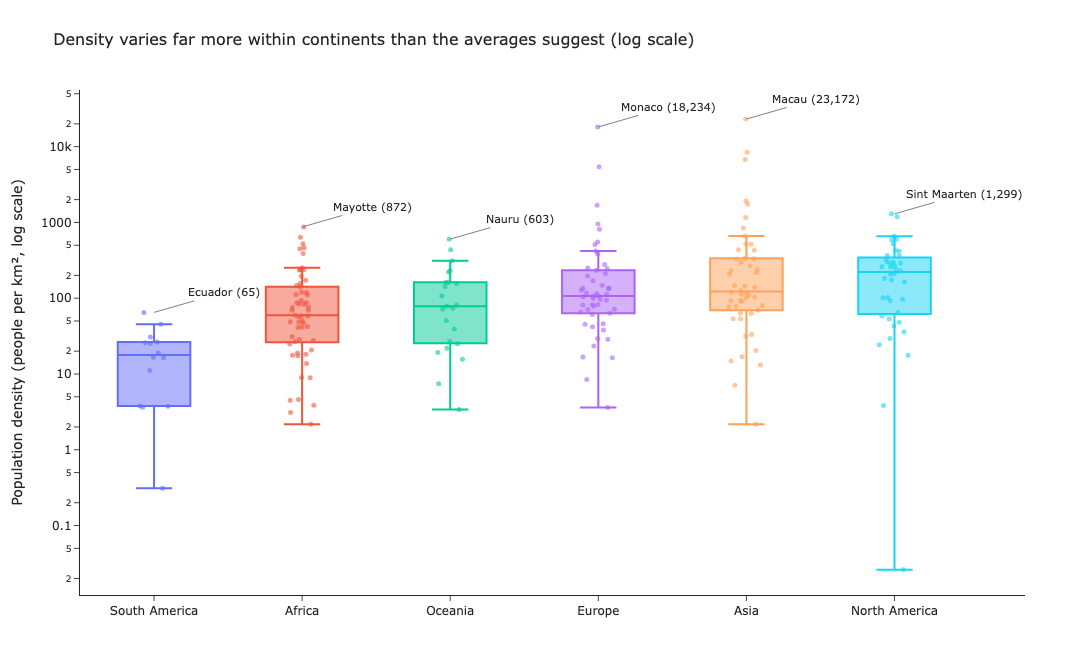

               count  min   25%    50%    75%      max    IQR  max / min
Continent                                                               
South America   14.0  0.3   5.6   17.8   26.4     65.0   20.7      209.0
Africa          57.0  2.2  26.6   59.7  140.3    871.9  113.7      403.0
Oceania         23.0  3.4  25.9   78.2  162.2    603.2  136.3      177.0
Europe          50.0  3.6  63.8  106.9  228.0  18234.5  164.2     5037.0
Asia            50.0  2.2  71.5  123.0  336.3  23172.3  264.8    10665.0
North America   40.0  0.0  63.3  221.4  335.5   1299.3  272.2    49780.0


In [12]:
# Q4
# YOUR CODE HERE
d = df[["Country", "Continent", "Density"]].dropna().copy()
d = d[d["Density"] > 0]

# 1. Order continents by median density (least to most crowded)
order = d.groupby("Continent")["Density"].median().sort_values().index.tolist()

# 2. Box plot with every country as a dot, log y-axis
fig = px.box(
    d, x="Continent", y="Density", color="Continent",
    points="all", hover_name="Country", log_y=True,
    category_orders={"Continent": order},
    labels={"Density": "Population density (people per km², log scale)"},
    title="Density varies far more within continents than the averages suggest (log scale)",
)
fig.update_traces(marker=dict(size=5, opacity=0.6), jitter=0.5, pointpos=0)

# 3. Label the densest country in each continent
densest = d.loc[d.groupby("Continent")["Density"].idxmax()]
for _, row in densest.iterrows():
    fig.add_annotation(
        x=row["Continent"], y=np.log10(row["Density"]),   # log axis needs log10 for y
        text=f'{row["Country"]} ({row["Density"]:,.0f})',
        showarrow=True, arrowhead=0, arrowcolor="gray",
        ax=70, ay=-20, font=dict(size=11),
        bgcolor="rgba(255,255,255,0.85)",
    )

fig.update_layout(
    template="simple_white", showlegend=False,
    height=650, width=1100,
    margin=dict(t=90, b=70, l=80, r=40),
    xaxis_title=None, title_font_size=16,
)
fig.show()

# 4. Numbers behind the spread (use these to write your conclusion)
summary = d.groupby("Continent")["Density"].describe(percentiles=[0.25, 0.5, 0.75])
summary["IQR"] = summary["75%"] - summary["25%"]
summary["max / min"] = (summary["max"] / summary["min"]).round(0)
print(summary[["count", "min", "25%", "50%", "75%", "max", "IQR", "max / min"]].round(1).loc[order])

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

**Chart: choropleth (world map) colored by % population change, 2000 to 2022.**

The question asks *where* countries grew or shrank, and only a map shows geography directly. A bar chart could rank the countries but would hide spatial patterns, such as shrinking countries clustering in Eastern Europe.

I used **percentage change** so countries of very different sizes can be compared fairly. The color scale runs from **red (shrank) through white (0%) to blue (grew)**, so the two groups separate at a glance. I capped the scale at +100% so a few extreme growers don't wash out the rest, and hover labels show each country's exact value and name.

The weakness of a map is that small countries are hard to see, so I also print the biggest shrinkers and growers below the chart.

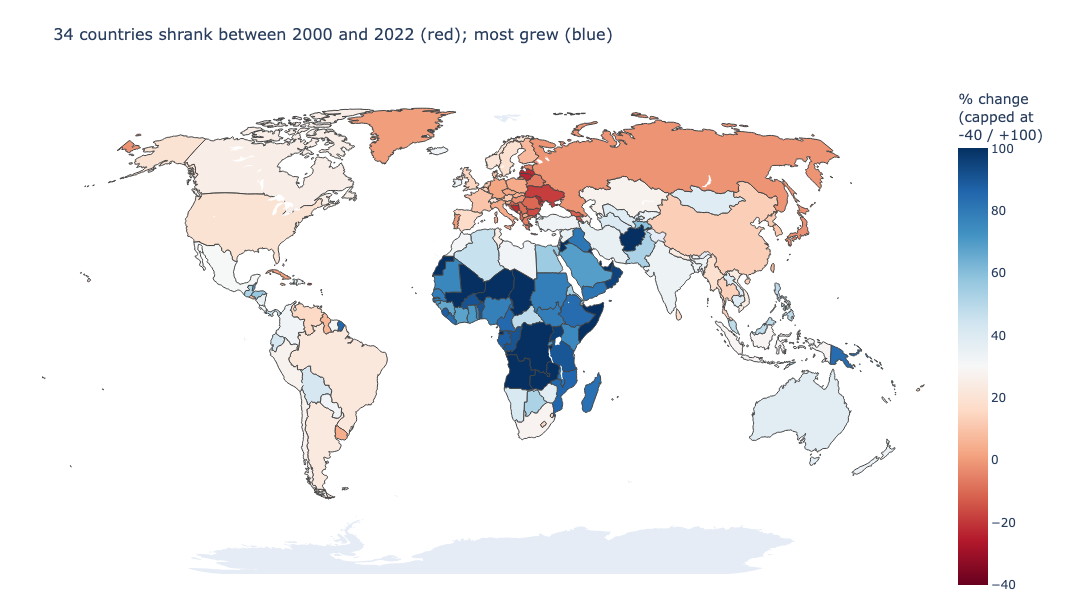

34 of 234 countries shrank.

Shrinking countries by continent:
Continent
Europe           18
North America     7
Oceania           6
Asia              3
Name: count, dtype: int64 

Biggest shrinkers:
                 Country Continent  Change_pct
Northern Mariana Islands   Oceania       -38.3
          American Samoa   Oceania       -24.0
               Lithuania    Europe       -23.6
        Marshall Islands   Oceania       -23.3
                 Moldova    Europe       -23.0
                  Latvia    Europe       -22.6
  Bosnia and Herzegovina    Europe       -22.6
            Vatican City    Europe       -21.7
       Wallis and Futuna   Oceania       -21.4
                 Ukraine    Europe       -18.8 

Biggest growers:
                 Country     Continent  Change_pct
                   Qatar          Asia       317.2
    United Arab Emirates          Asia       188.2
       Equatorial Guinea        Africa       144.5
Turks and Caicos Islands North America       143.8
         

In [13]:
# Q5
# YOUR CODE HERE
d = df[["CCA3", "Country", "Continent", "2000 Population", "2022 Population"]].dropna().copy()
d = d[d["2000 Population"] > 0]

# 1. Percentage change 2000 -> 2022
d["Change_pct"] = (d["2022 Population"] / d["2000 Population"] - 1) * 100
d["Trend"] = np.where(d["Change_pct"] < 0, "Shrank", "Grew")

# 2. Clip the color range so a few extreme growers don't wash out the map
d["Change_clipped"] = d["Change_pct"].clip(-40, 100)

# 3. Choropleth with a diverging scale centered on 0
fig = px.choropleth(
    d, locations="CCA3", color="Change_clipped",
    hover_name="Country",
    hover_data={"CCA3": False, "Change_clipped": False,
                "Change_pct": ":.1f", "Continent": True},
    color_continuous_scale="RdBu",      # red = shrank, blue = grew
    color_continuous_midpoint=0,
    range_color=(-40, 100),
    labels={"Change_clipped": "% change", "Change_pct": "% change, 2000 to 2022"},
    title=f"{(d['Trend'] == 'Shrank').sum()} countries shrank between 2000 and 2022 (red); most grew (blue)",
)
fig.update_geos(showframe=False, showcoastlines=False, projection_type="natural earth")
fig.update_layout(
    height=600, width=1100,
    margin=dict(t=80, b=20, l=20, r=20),
    title_font_size=16,
    coloraxis_colorbar=dict(title="% change<br>(capped at<br>-40 / +100)"),
)
fig.show()

# 4. The numbers behind the map (use these to write your conclusion)
shrank = d[d["Trend"] == "Shrank"].sort_values("Change_pct")
print(f"{len(shrank)} of {len(d)} countries shrank.\n")
print("Shrinking countries by continent:")
print(shrank["Continent"].value_counts(), "\n")
print("Biggest shrinkers:")
print(shrank[["Country", "Continent", "Change_pct"]].head(10).round(1).to_string(index=False), "\n")
print("Biggest growers:")
print(d.nlargest(10, "Change_pct")[["Country", "Continent", "Change_pct"]].round(1).to_string(index=False))

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

### Chart choice & justification

**Chart: treemap of 2022 world population, grouped by continent and then by country.**

Q6 wants two levels, continents and the countries inside them, shown together in one figure. A treemap is made for this. Each continent becomes a large rectangle, and that rectangle is split into smaller ones, one per country. The area of every rectangle matches its population, so you can see at a glance which continents and countries hold the biggest shares of the 8 billion.

Each continent has its own color, which makes the grouping easy to follow. Hovering over a country shows its exact population and share of the world. Very small countries end up as tiny rectangles, so labels appear only where there is room. A pie chart was not a good fit because it shows just one level, and about 230 slices would be impossible to read.

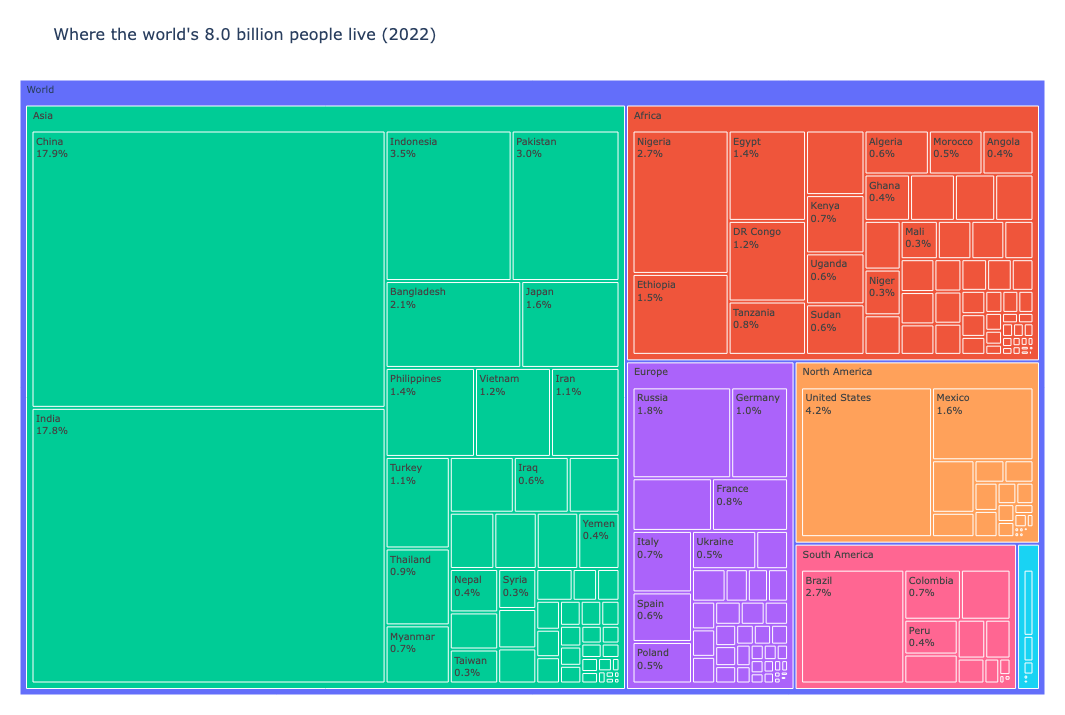

               Population (M)  Share (%)
Continent                               
Asia                   4721.0       59.2
Africa                 1427.0       17.9
Europe                  743.0        9.3
North America           600.0        7.5
South America           437.0        5.5
Oceania                  45.0        0.6

Top 5 countries share of world: 46.3 %
      Country     Continent  Share
        China          Asia   17.9
        India          Asia   17.8
United States North America    4.2
    Indonesia          Asia    3.5
     Pakistan          Asia    3.0


In [26]:
# Your code here
d = df[["Country", "Continent", "2022 Population"]].dropna().copy()
d = d[d["2022 Population"] > 0]
d["Share"] = d["2022 Population"] / d["2022 Population"].sum() * 100

total_bn = d["2022 Population"].sum() / 1e9

# Treemap: World > Continent > Country
fig = px.treemap(
    d, path=[px.Constant("World"), "Continent", "Country"],
    values="2022 Population", color="Continent",
    custom_data=["Share"],
    title=f"Where the world's {total_bn:.1f} billion people live (2022)",
)
fig.update_traces(
    texttemplate="%{label}<br>%{customdata[0]:.1f}%",
    hovertemplate="<b>%{label}</b><br>Population: %{value:,.0f}<br>"
                  "Share of world: %{customdata[0]:.2f}%<extra></extra>",
    textfont_size=13,
    root_color="white",
)
fig.update_layout(
    height=700, width=1100,
    margin=dict(t=80, b=20, l=20, r=20),
    title_font_size=16,
    uniformtext=dict(minsize=9, mode="hide"),   # hides labels that don't fit
)
fig.show()

# Numbers behind the chart (use these to write your conclusion)
cont = (d.groupby("Continent")["2022 Population"].sum() / 1e6).round(0)
cont_share = (cont / cont.sum() * 100).round(1)
print(pd.DataFrame({"Population (M)": cont, "Share (%)": cont_share}).sort_values("Share (%)", ascending=False))
print("\nTop 5 countries share of world:", d.nlargest(5, "Share")["Share"].sum().round(1), "%")
print(d.nlargest(5, "Share")[["Country", "Continent", "Share"]].round(1).to_string(index=False))

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*
**Chart: 100% stacked area chart of world population share, 1970 to 2022, for Africa, Asia, Europe and Rest of the world.**

The question is about shares of one whole that change over time. In a 100% stacked area chart the layers always add up to the full world population, so a band that gets thicker is a rising share and one that gets thinner is a falling share. A line chart would show the same numbers, but it would not make clear that the groups together make up 100%.

I grouped the other three continents as "Rest of the world", as the question asks, which keeps the chart to four readable bands. Each band is labeled directly with its 1970 and 2022 share, so the change can be read without a legend. Years are placed on a numeric axis so the uneven gaps (1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022) are spaced correctly.

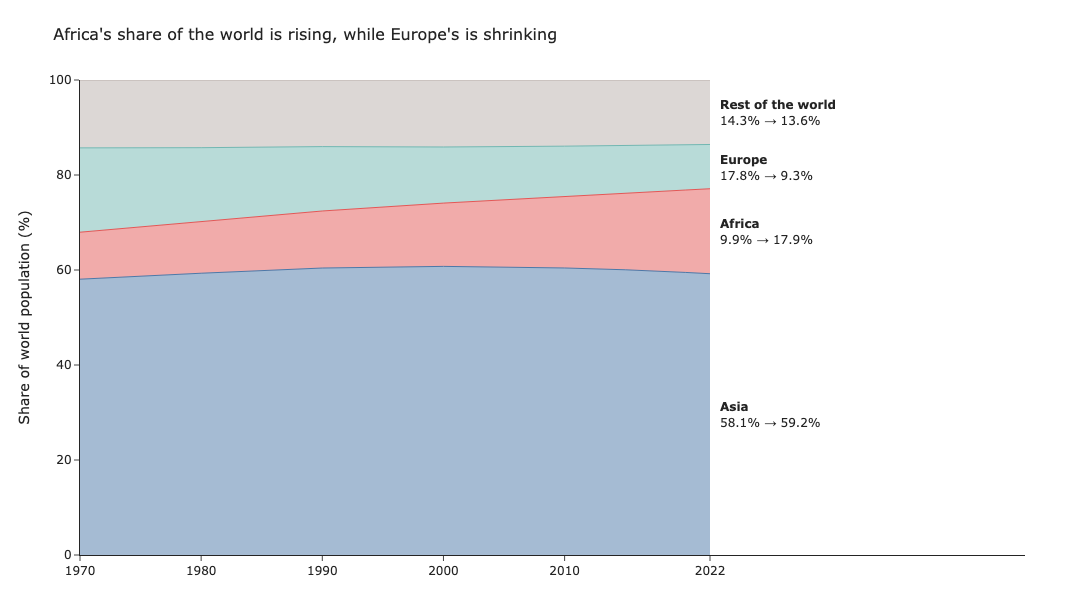

                   1970 (%)  2022 (%)  Change (pp)
Continent                                         
Asia                   58.1      59.2          1.2
Africa                  9.9      17.9          8.0
Europe                 17.8       9.3         -8.4
Rest of the world      14.3      13.6         -0.7


In [24]:
# Q7
# YOUR CODE HERE
pop_cols = [c for c in df.columns if c.endswith("Population")]
by_cont = df.groupby("Continent")[pop_cols].sum()
by_cont.columns = [int(c.split()[0]) for c in pop_cols]

# 2. Group: Africa, Asia, Europe, and everything else as "Rest of the world"
keep = ["Africa", "Asia", "Europe"]
grouped = by_cont.loc[keep].copy()
grouped.loc["Rest of the world"] = by_cont.drop(keep).sum()

# 3. Shares in % of the world total for each year
share = grouped / grouped.sum() * 100
long = (share.T.sort_index().reset_index()
             .rename(columns={"index": "Year"})
             .melt(id_vars="Year", var_name="Group", value_name="Share"))

# 4. 100% stacked area chart
order = ["Asia", "Africa", "Europe", "Rest of the world"]
fig = px.area(
    long, x="Year", y="Share", color="Group",
    category_orders={"Group": order},
    color_discrete_map={"Asia": "#4c78a8", "Africa": "#e45756",
                        "Europe": "#72b7b2", "Rest of the world": "#bab0ac"},
    title="Africa's share of the world is rising, while Europe's is shrinking",
)
fig.update_traces(line_width=1)

# 5. Direct labels with 1970 -> 2022 share (replaces the legend)
cum_2022 = 0
for g in order:
    s70, s22 = share.loc[g, 1970], share.loc[g, 2022]
    fig.add_annotation(x=2022, y=cum_2022 + s22 / 2,
                       text=f"<b>{g}</b><br>{s70:.1f}% → {s22:.1f}%",
                       showarrow=False, xanchor="left", xshift=8, align="left")
    cum_2022 += s22

fig.update_layout(
    template="simple_white", showlegend=False,
    height=600, width=1100,
    margin=dict(t=80, b=60, l=80, r=40),
    title_font_size=16,
    yaxis=dict(title="Share of world population (%)", range=[0, 100]),
    xaxis=dict(title=None, range=[1970, 2048], tickvals=[1970, 1980, 1990, 2000, 2010, 2022]),
)
fig.show()

# 6. Numbers behind the chart (use these to write your conclusion)
change = pd.DataFrame({"1970 (%)": share[1970], "2022 (%)": share[2022]})
change["Change (pp)"] = change["2022 (%)"] - change["1970 (%)"]
print(change.round(1).loc[order])